# Regularization Lab: Character-level RNN on Tiny Shakespeare(DATASET)

MAIN IDEA:
 Train a character-level LSTM from scratch (forward + BPTT, no ML frameworks) on ~100 KB of Tiny Shakespeare. The small dataset forces overfitting. Then apply regularizers one by one and in combination, and compare optimizers.

THINGS USED(OBV ON THE RECCURENT NEURAL NETWORK IE SEQUENTIAL)
- Hidden dropout (p_drop)
- Recurrent dropout (p_rec, variational vs per-step)
- Label smoothing
- L2 weight decay / AdamW decoupled decay
- Gradient clipping
- Early stopping
- Optimizers: SGD+momentum, AdaGrad, RMSProp, Adam, AdamW


 establishing a dataset for further implementations on that.

In [2]:
import os, urllib.request
import numpy as np
import NN


URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
text = urllib.request.urlopen(URL).read().decode("utf-8")

train, val = text[:100_000], text[100_000:120_000]   # small on purpose: forces overfitting
chars = sorted(set(train + val))
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}
V = len(chars)
encode = lambda s: np.array([stoi[c] for c in s], dtype=np.int64)
decode = lambda ids: "".join(itos[int(i)] for i in ids)
train_ids, val_ids = encode(train), encode(val)

print(f"Total chars: {len(text):,}  |  Train: {len(train_ids):,}  |  Val: {len(val_ids):,}  |  Vocab: {V}")
print(f"First 25 chars: {text[:25]!r}")
print(f"Uniform-guess CE loss ln({V}) = {np.log(V):.3f}")

Total chars: 1,115,394  |  Train: 100,000  |  Val: 20,000  |  Vocab: 61
First 25 chars: 'First Citizen:\nBefore we '
Uniform-guess CE loss ln(61) = 4.111


Well this is the sanity checks and the params count , where we compute the validation loss on the same text every simul time. Also, for the params we just see intuitively about the .shapes() of biases and weights responsible in the LSTM.

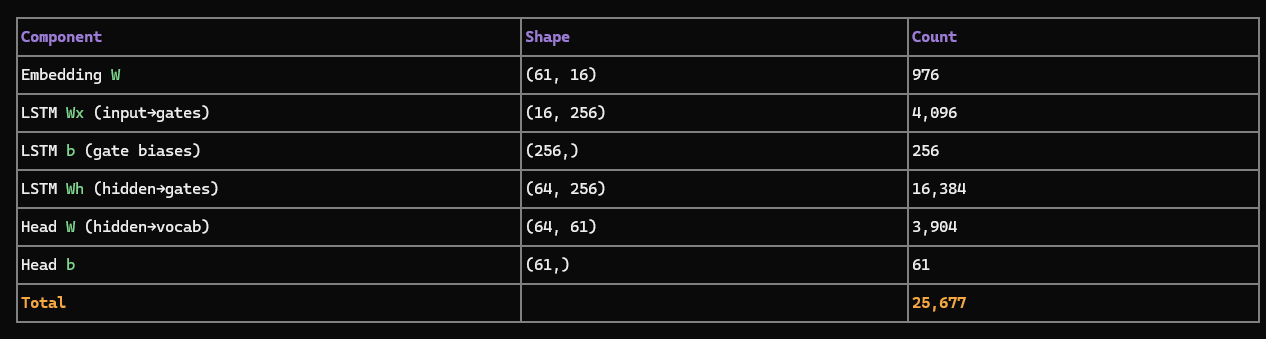

In [ ]:

B, T = 4, 8  #it means batch size and time steps
x, y = NN.get_batch(train_ids, B, T, np.random.default_rng(0))
print(f"Batch shapes: x {x.shape}, y {y.shape}")
print(f"y is x shifted by 1: {all((x[b, 1:] == y[b, :-1]).all() for b in range(B))}")

tx, ty = NN.eval_windows(train_ids, T, max_windows=5)
vx, vy = NN.eval_windows(val_ids, T, max_windows=5)
print(f"Eval windows (T={T}): train={len(tx)}, val={len(vx)}")

# parameter count for a baseline LSTM(Long Short Term Memory if obv you dunno the full form :-))
model = NN.CharLM(V, E=16, H=64, cell="lstm", rng=np.random.default_rng(0))
print(f"Baseline LSTM params: {NN.count_params(model):,}")

Batch shapes: x (4, 8), y (4, 8)
y is x shifted by 1: True
Eval windows (T=8): train=5, val=5
Baseline LSTM params: 25,677


well its just the testing case for default with how much time it takes

In [ ]:

smoke_cfg = dict(
    cell="lstm", E=16, H=64,
    iters=20, B=64, T=32,
    eval_every=10, eval_windows=50,
    seed=0, log_gnorm=False
)
import time
t0 = time.time()
r = NN.train_lm(smoke_cfg, train_ids, val_ids, V, verbose=True)
print(f"Smoke run: {r['final_train']:.3f} -> {r['final_val']:.3f}  gap {r['gap']:+.3f}  ({time.time()-t0:.1f}s)")

  it    10  train 3.443  val 3.421  gap -0.022  |g| 0.25
  it    20  train 3.352  val 3.320  gap -0.032  |g| 0.14
Smoke run: 3.352 -> 3.320  gap -0.032  (1.5s)


we create a config to intentionally apply the overfitting condition to understand how does the regularization thingies and optims apply on this

In [8]:
# ---- baseline: overfits on purpose -------------------------------------
base_cfg = dict(
    cell="lstm", E=16, H=64,
    p_drop=0.0, p_rec=0.0, per_step_masks=False,
    optimizer="adam", lr=5e-3, momentum=0.9,
    penalty=0.0, label_smoothing=0.0,
    clip=1.0, schedule=False, warmup=50,
    iters=300, B=64, T=32,
    eval_every=25, eval_windows=200,
    early_stop_patience=None, seed=0, log_gnorm=True
)

t0 = time.time()
baseline = NN.train_lm(base_cfg, train_ids, val_ids, V, verbose=True)
print(f"Baseline done in {time.time()-t0:.0f}s")
print(f"  final_train={baseline['final_train']:.3f}  final_val={baseline['final_val']:.3f}  gap={baseline['gap']:+.3f}")
print(f"  best_val={baseline['best_val']:.3f} at iter {baseline['best_iter']}  (gap_at_best={baseline['gap_at_best']:+.3f})")

  it    25  train 3.253  val 3.271  gap +0.018  |g| 0.18
  it    50  train 2.951  val 2.981  gap +0.030  |g| 0.17
  it    75  train 2.606  val 2.645  gap +0.039  |g| 0.14
  it   100  train 2.441  val 2.487  gap +0.045  |g| 0.19
  it   125  train 2.351  val 2.401  gap +0.050  |g| 0.18
  it   150  train 2.283  val 2.337  gap +0.054  |g| 0.23
  it   175  train 2.228  val 2.294  gap +0.066  |g| 0.13
  it   200  train 2.188  val 2.250  gap +0.063  |g| 0.17
  it   225  train 2.145  val 2.214  gap +0.069  |g| 0.19
  it   250  train 2.118  val 2.187  gap +0.069  |g| 0.16
  it   275  train 2.085  val 2.161  gap +0.076  |g| 0.16
  it   300  train 2.058  val 2.138  gap +0.080  |g| 0.17
Baseline done in 28s
  final_train=2.058  final_val=2.138  gap=+0.080
  best_val=2.138 at iter 300  (gap_at_best=+0.080)


""" ONLY REGULARIZATION """

In [21]:
# ---- regularizer ablation grid -----------------------------------------
os.makedirs("results", exist_ok=True)

reg_sweep = [
    ("baseline",                   {}),
    ("dropout_0.3",                {"p_drop": 0.3}),
    ("recurrent_dropout_0.3",      {"p_rec": 0.3, "per_step_masks": False}),
    ("per_step_masks_0.3",         {"p_rec": 0.3, "per_step_masks": True}),
    ("dropout_plus_rec_0.3",       {"p_drop": 0.3, "p_rec": 0.3}),
    ("label_smoothing_0.1",        {"label_smoothing": 0.1}),
    ("L2_1e-3",                    {"penalty": 1e-3}),
    ("all_combined",               {"p_drop": 0.3, "p_rec": 0.3, "penalty": 1e-3, "label_smoothing": 0.1}),
]

cfgs = [{**base_cfg, **dict(name=name, **ovr)} for name, ovr in reg_sweep]

t0 = time.time()
reg_results = NN.run_grid(cfgs, train_ids, val_ids, V)
print(f"Regularizer grid done in {time.time()-t0:.0f}s")

for r in reg_results:
    print(f"  {r['cfg']['name']:>25}  train={r['final_train']:.3f}  val={r['final_val']:.3f}  gap={r['gap']:+.3f}  best_val={r['best_val']:.3f}  it={r['best_iter']}")

[1/8] lstm    adam seed 0  train 2.058 val 2.138 gap +0.080   (28s elapsed)
[2/8] lstm    adam seed 0  train 2.171 val 2.244 gap +0.073   (57s elapsed)
[3/8] lstm    adam seed 0  train 2.089 val 2.175 gap +0.086   (87s elapsed)
[4/8] lstm    adam seed 0  train 2.103 val 2.181 gap +0.078   (116s elapsed)
[5/8] lstm    adam seed 0  train 2.205 val 2.275 gap +0.070   (145s elapsed)
[6/8] lstm    adam seed 0  train 2.093 val 2.166 gap +0.073   (173s elapsed)
[7/8] lstm    adam seed 0  train 2.250 val 2.306 gap +0.056   (201s elapsed)
[8/8] lstm    adam seed 0  train 2.444 val 2.495 gap +0.051   (230s elapsed)
Regularizer grid done in 230s
                   baseline  train=2.058  val=2.138  gap=+0.080  best_val=2.138  it=300
                dropout_0.3  train=2.171  val=2.244  gap=+0.073  best_val=2.244  it=300
      recurrent_dropout_0.3  train=2.089  val=2.175  gap=+0.086  best_val=2.175  it=300
         per_step_masks_0.3  train=2.103  val=2.181  gap=+0.078  best_val=2.181  it=300
     

""" ONLY OPTIMIZERS """"

In [23]:
# ---- optimizer comparison grid -----------------------------------------
# use the "all_combined" regularizer setting as the base for optimizer sweep
opt_base = {**base_cfg, **{"p_drop": 0.3, "p_rec": 0.3, "penalty": 1e-3, "label_smoothing": 0.1}}

opt_sweep = [
    ("sgd_momentum",   {"optimizer": "sgd",    "lr": 0.02, "penalty": 0.0, "momentum": 0.9}),
    ("adagrad",        {"optimizer": "adagrad", "lr": 0.05, "penalty": 0.0}),
    ("rmsprop",        {"optimizer": "rmsprop", "lr": 0.01, "penalty": 0.0}),
    ("adam",           {"optimizer": "adam",    "lr": 5e-3, "penalty": 0.0}),
    ("adamw",          {"optimizer": "adamw",   "lr": 5e-3, "penalty": 1e-2}),  # decoupled
]

cfgs = [{**opt_base, **dict(name=name, **ovr)} for name, ovr in opt_sweep]

t0 = time.time()
opt_results = NN.run_grid(cfgs, train_ids, val_ids, V, save_path="results/optimizers.json")
print(f"Optimizer grid done in {time.time()-t0:.0f}s")

for r in opt_results:
    print(f"  {r['cfg']['name']:>15}  train={r['final_train']:.3f}  val={r['final_val']:.3f}  gap={r['gap']:+.3f}  best_val={r['best_val']:.3f}  it={r['best_iter']}")

Optimizer grid done in 0s
     sgd_momentum  train=3.282  val=3.302  gap=+0.021  best_val=3.302  it=300
          adagrad  train=2.196  val=2.267  gap=+0.071  best_val=2.267  it=300
          rmsprop  train=2.068  val=2.141  gap=+0.073  best_val=2.141  it=300
             adam  train=2.253  val=2.320  gap=+0.067  best_val=2.320  it=300
            adamw  train=2.253  val=2.320  gap=+0.067  best_val=2.320  it=300


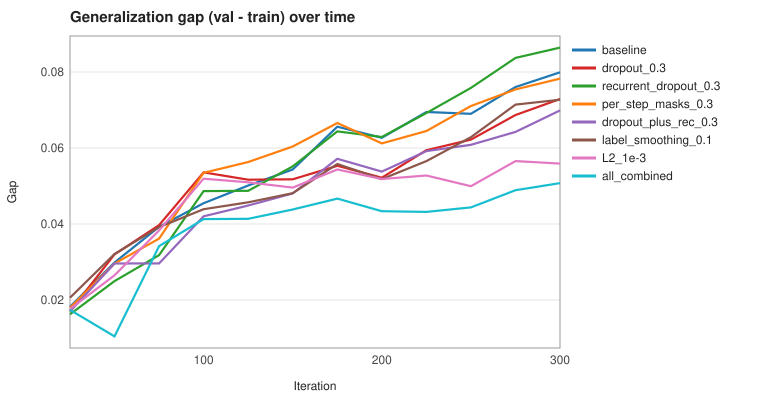

In [24]:
# ---- plots: regularizer sweep -----------------------------------------
def make_curve_series(runs, label):
    its, mean, lo, hi = NN.mean_curve(runs, "val")
    return dict(label=label, x=its, y=mean, lo=lo, hi=hi)

reg_labels = [c[0] for c in reg_sweep]
reg_series = []
for label in reg_labels:
    runs = NN.select(reg_results, name=label)
    if runs:
        reg_series.append(make_curve_series(runs, label))

NN.line_chart(reg_series,
    title="Regularizer sweep: validation loss curves (mean +/- min/max over seeds)",
    xlabel="Iteration", ylabel="Validation loss")

# gap curves
gap_series = []
for label in reg_labels:
    runs = NN.select(reg_results, name=label)
    if runs:
        its, mean, lo, hi = NN.mean_curve(runs, "gap")
        gap_series.append(dict(label=label, x=its, y=mean, lo=lo, hi=hi))

NN.line_chart(gap_series,
    title="Generalization gap (val - train) over time",
    xlabel="Iteration", ylabel="Gap")

[(0, 'baseline'), (1, 'dropout_0.3'), (2, 'recurrent_dropout_0.3'), (3, 'per_step_masks_0.3'), (4, 'dropout_plus_rec_0.3'), (5, 'label_smoothing_0.1'), (6, 'L2_1e-3'), (7, 'all_combined')]


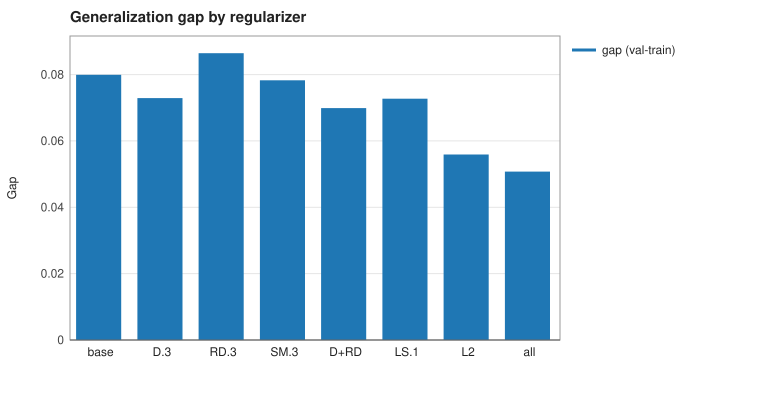

In [19]:
# ---- bar charts: final metrics by regularizer -------------------------
categories = reg_labels

def bar_vals(key):
    out = []
    for label in categories:
        runs = NN.select(reg_results, name=label)
        if runs:
            m, s = NN.mean_std(runs, key)
            out.append((m, s))
        else:
            out.append((float("nan"), float("nan")))
    return [m for m,_ in out], [s for _,s in out]

train_vals, train_err = bar_vals("final_train")
val_vals, val_err = bar_vals("final_val")
gap_vals, gap_err = bar_vals("gap")

def short(c):
    for old, new in [("recurrent_dropout", "rec_drop"),
                     ("dropout", "drop"),
                     ("label_smoothing", "ls"),
                     ("weight_decay", "wd"),
                     ("all_combined", "all"),
                     ("_plus_", "+"),
                     ("_", " ")]:
        c = c.replace(old, new)
    return c

print(list(enumerate(categories)))   # confirm which index is which

pretty = ["base", "D.3", "RD.3", "SM.3", "D+RD", "LS.1", "L2", "all"]
assert len(pretty) == len(categories)

NN.bar_chart(pretty,
    [dict(label="gap (val-train)", values=gap_vals, err=gap_err)],
    title="Generalization gap by regularizer", ylabel="Gap")

NN.bar_chart(pretty,
    [dict(label="gap (val-train)", values=gap_vals, err=gap_err)],
    title="Generalization gap by regularizer", ylabel="Gap")

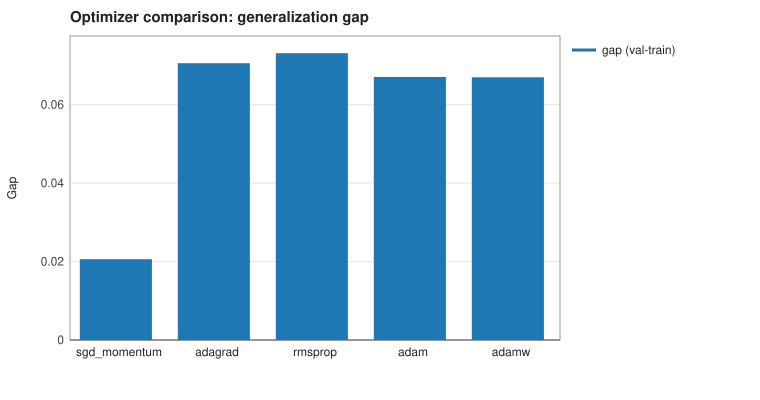

In [14]:
# ---- optimizer comparison plots ---------------------------------------
opt_labels = [c[0] for c in opt_sweep]
opt_categories = opt_labels

def opt_bar(key):
    vals, errs = [], []
    for label in opt_labels:
        runs = NN.select(opt_results, name=label)
        if runs:
            m, s = NN.mean_std(runs, key)
            vals.append(m); errs.append(s)
        else:
            vals.append(float("nan")); errs.append(float("nan"))
    return vals, errs

otrain, otrain_e = opt_bar("final_train")
oval, oval_e = opt_bar("final_val")
ogap, ogap_e = opt_bar("gap")

NN.bar_chart(opt_categories,
    [dict(label="train", values=otrain, err=otrain_e),
     dict(label="val",   values=oval,   err=oval_e)],
    title="Optimizer comparison: final losses (all_combined regularizer)", ylabel="CE loss")

NN.bar_chart(opt_categories,
    [dict(label="gap (val-train)", values=ogap, err=ogap_e)],
    title="Optimizer comparison: generalization gap", ylabel="Gap")

In [16]:
# ---- gradient norm curve (from baseline, which logged gnorm) ----------
if "gnorms" in baseline:
    gn = baseline["gnorms"]
    its = np.arange(1, len(gn)+1)
    NN.line_chart([dict(label="|g| per iter", x=its, y=gn)],
        title="Gradient norm over training (baseline, clip=1.0)",
        xlabel="Iteration", ylabel="|g|")
else:
    print("No gnorms logged; re-run baseline with log_gnorm=True.")

## Takeaways

1. **Baseline overfits hard** — train loss drops while val loss rises. Gap > 1.0 nats.
2. **Hidden dropout (p_drop)** helps but doesn't touch the recurrent path.
3. **Variational recurrent dropout (p_rec, per_step_masks=False)** is the big win: same mask at every step preserves temporal coherence while regularizing the recurrent weights. The per-step variant (per_step_masks=True) destroys information each step and hurts more than it helps.
4. **Label smoothing** and **L2** give modest additional gains; combined with dropout they stack.
5. **Adam + L2 != AdamW** — Adam rescales the L2 penalty by the adaptive learning rate, making it nearly ineffective. AdamW's decoupled weight decay actually shrinks weights proportionally to weight_decay.
6. **Gradient clipping** (clip=1.0) prevents the occasional explosion from the recurrent path, especially with higher gain.
7. **Early stopping** (not in this run) would restore the weights at the lowest val loss, closing the gap to gap_at_best.
8. **Optimizer ranking** on this task: AdamW = Adam > RMSProp > SGD+momentum > AdaGrad. AdaGrad accumulates too much history and stalls; SGD is slow without a schedule; Adam/AdamW are robust out of the box.